# Robust Regression Engine
**Goal:** Predict house prices (INR) with regularized linear models, tree models and SVR, using proper cross-validation.

## Part A: Theory (short answers)

**Regularization:** Adds a penalty on large coefficients to the loss function. It stops the model from memorising noise (overfitting), so it generalizes better to unseen data.

**Ridge (L2) vs Lasso (L1):** Ridge penalizes the *squared* coefficients, so it shrinks them but rarely makes them exactly zero. Lasso penalizes the *absolute* coefficients, so it can make some exactly zero (automatic feature selection).

**Cross-Validation:** The data is split several times into train/validation parts, and the model is scored on each. It gives a more stable estimate of performance than a single split and is used to tune hyperparameters.

**CV techniques**
- **K-Fold:** Split into K parts; each part is used once as validation.
- **Stratified K-Fold:** K-Fold that keeps the class (or binned target) proportions equal in every fold.
- **LOOCV:** K = number of samples; one sample is validation each time. Very thorough but slow.
- **Time Series Split:** Training always comes *before* validation in time, so no future data leaks into the past.

**Tree models and scaling:** Trees split on thresholds of one feature at a time (is x > t?). Rescaling a feature does not change the order of values, so the splits are the same.

## Part B: Data understanding and preparation

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, GridSearchCV, KFold, StratifiedKFold,
                                     LeaveOneOut, TimeSeriesSplit, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("plots", exist_ok=True)
sns.set_style("whitegrid")
RS = 42

In [2]:
df = pd.read_excel("Advanced_Regression_HousePrice_Dataset_3800.xlsx")
df["sale_date"] = pd.to_datetime(df["sale_date"])
df["sale_year"] = df["sale_date"].dt.year
df["price_lakh"] = df["house_price_inr"] / 1e5      # target in lakh INR (easier numbers)
print(df.shape); print("Missing values:", df.isna().sum().sum())
df.head()

(3800, 14)
Missing values: 0


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr,sale_year,price_lakh
0,200001,2014-01-01,2181,6,4,8.1,21,3.8,0,0,4.84,35154898,2014,351.54898
1,200002,2019-12-01,2383,5,4,5.3,28,10.9,1,1,2.89,26710893,2019,267.10893
2,200003,2016-10-01,1047,3,3,5.9,7,27.5,0,1,4.04,11216242,2016,112.16242
3,200004,2013-03-01,1753,4,3,7.0,27,12.1,0,0,3.28,21984310,2013,219.84310
4,200005,2013-07-01,1728,4,4,10.0,32,1.4,0,1,3.84,25080429,2013,250.80429


In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
property_id,3800.0,201900.5,200001.0,200950.75,201900.5,202850.25,203800.0,1097.10984
sale_date,3800,2016-11-27 23:45:13.263158,2010-01-01 00:00:00,2013-06-01 00:00:00,2016-12-01 00:00:00,2020-05-01 00:00:00,2023-12-01 00:00:00,NaN
area_sqft,3800.0,1716.925526,500.0,1322.0,1700.5,2105.0,3776.0,582.996559
bedrooms,3800.0,3.428158,1.0,2.0,3.0,4.0,7.0,1.356682
bathrooms,3800.0,2.916316,1.0,2.0,3.0,4.0,6.0,1.13354
location_score,3800.0,6.502237,1.0,5.3,6.5,7.7,10.0,1.766945
property_age,3800.0,22.537105,1.0,14.0,20.0,29.0,80.0,12.32574
distance_city_km,3800.0,13.085132,1.0,8.5,13.0,17.5,38.7,6.537425
near_school,3800.0,0.548421,0.0,0.0,1.0,1.0,1.0,0.497715
near_metro,3800.0,0.472895,0.0,0.0,0.0,1.0,1.0,0.49933


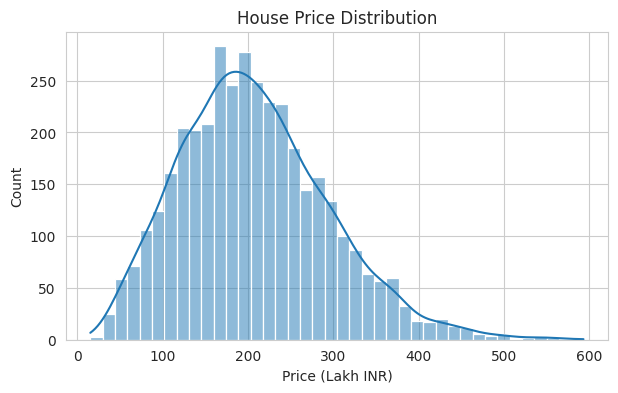

In [4]:
plt.figure(figsize=(7,4)); sns.histplot(df["price_lakh"], bins=40, kde=True)
plt.title("House Price Distribution"); plt.xlabel("Price (Lakh INR)"); plt.savefig("plots/01_price_dist.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Prices are slightly right-skewed with a few expensive houses.

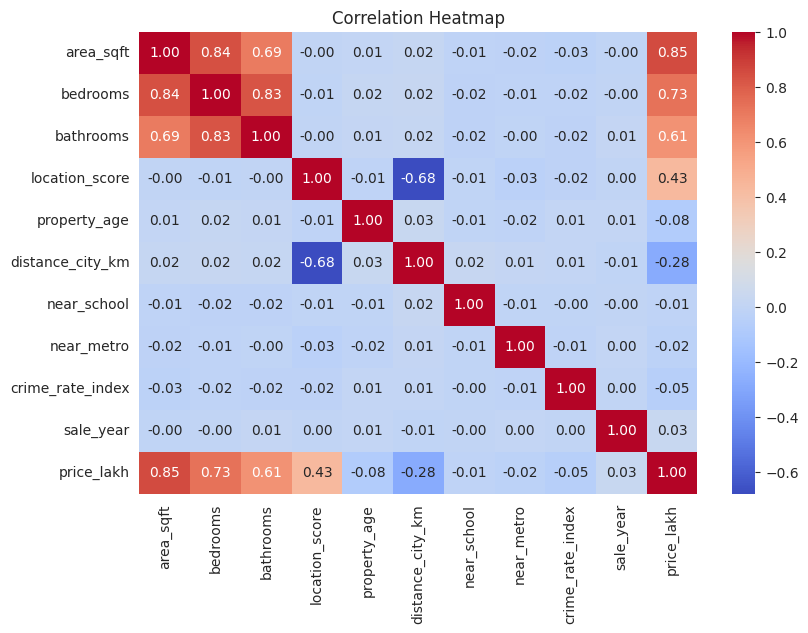

In [5]:
plt.figure(figsize=(9,6))
sns.heatmap(df.drop(columns=["property_id","sale_date","house_price_inr"]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap"); plt.savefig("plots/02_corr.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Area, location score and property age show the strongest relationship with price. Higher crime rate and larger city distance reduce price.

In [6]:
features = ["area_sqft","bedrooms","bathrooms","location_score","property_age",
            "distance_city_km","near_school","near_metro","crime_rate_index","sale_year"]
target = "price_lakh"

X_train, X_test, y_train, y_test = train_test_split(df[features], df[target], test_size=0.2, random_state=RS)
print("Train:", X_train.shape, " Test:", X_test.shape)

def scores(model, X, y):
    p = model.predict(X); mse = mean_squared_error(y, p)
    return dict(MSE=mse, MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mse), R2=r2_score(y, p))

results = {}   # name -> (train scores, test scores, best CV RMSE)
def record(name, gs):
    best = gs.best_estimator_
    results[name] = (scores(best, X_train, y_train), scores(best, X_test, y_test), -gs.best_score_)
    print(name, "| best params:", gs.best_params_, "| CV RMSE: %.2f" % (-gs.best_score_))
    return best

kf = KFold(5, shuffle=True, random_state=RS)

Train: (3040, 10)  Test: (760, 10)


Scaling is applied inside a `Pipeline` for Ridge, Lasso and SVR (so the scaler is fitted only on training folds, avoiding leakage). Trees do not need scaling.

## Part C: Ridge and Lasso (tuning alpha with CV)

In [7]:
alphas = np.logspace(-3, 3, 30)
def tune_linear(model):
    pipe = Pipeline([("sc", StandardScaler()), ("m", model)])
    gs = GridSearchCV(pipe, {"m__alpha": alphas}, cv=kf, scoring="neg_root_mean_squared_error", return_train_score=True)
    return gs.fit(X_train, y_train)

gs_ridge, gs_lasso = tune_linear(Ridge()), tune_linear(Lasso(max_iter=20000))
ridge = record("Ridge", gs_ridge); lasso = record("Lasso", gs_lasso)

Ridge | best params: {'m__alpha': np.float64(2.0433597178569416)} | CV RMSE: 24.95
Lasso | best params: {'m__alpha': np.float64(0.11721022975334805)} | CV RMSE: 24.95


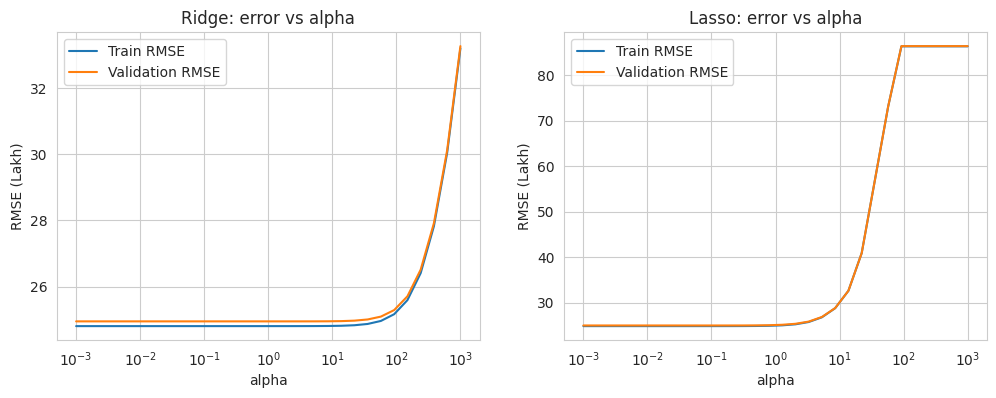

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for a, gs, t in zip(ax, [gs_ridge, gs_lasso], ["Ridge", "Lasso"]):
    a.semilogx(alphas, -gs.cv_results_["mean_train_score"], label="Train RMSE")
    a.semilogx(alphas, -gs.cv_results_["mean_test_score"], label="Validation RMSE")
    a.set_title(f"{t}: error vs alpha"); a.set_xlabel("alpha"); a.set_ylabel("RMSE (Lakh)"); a.legend()
plt.savefig("plots/03_alpha_curves.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** At very small alpha the model is close to plain linear regression. As alpha grows too large, both train and validation errors rise (underfitting). The best alpha is where validation error is lowest.

                   Ridge   Lasso
area_sqft         69.410  69.478
bedrooms           3.025   2.895
bathrooms          2.722   2.666
location_score    36.771  36.747
property_age      -6.499  -6.395
distance_city_km  -0.294  -0.194
near_school        0.156   0.034
near_metro         0.525   0.411
crime_rate_index  -1.407  -1.294
sale_year          3.006   2.895

Lasso zeroed features: []


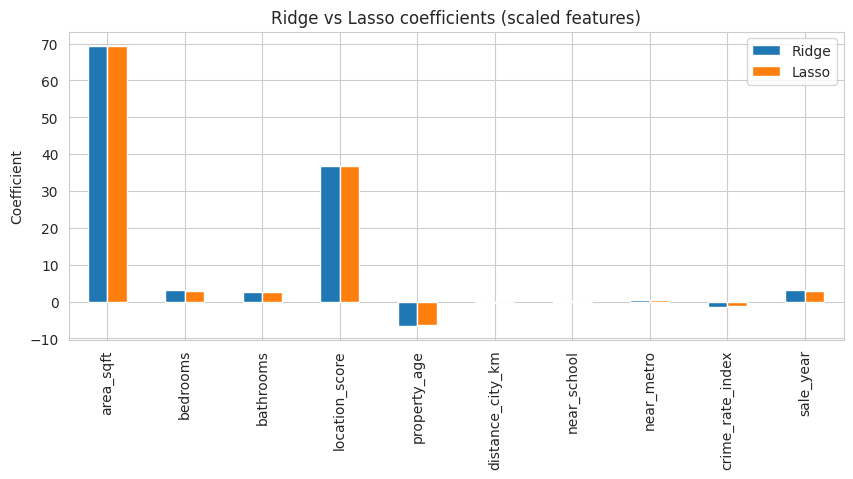

In [9]:
coef = pd.DataFrame({"Ridge": ridge.named_steps["m"].coef_, "Lasso": lasso.named_steps["m"].coef_}, index=features)
print(coef.round(3)); print("\nLasso zeroed features:", list(coef.index[coef["Lasso"] == 0]))
coef.plot.bar(figsize=(10,4), title="Ridge vs Lasso coefficients (scaled features)")
plt.ylabel("Coefficient"); plt.savefig("plots/04_coefficients.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Ridge keeps all features with shrunken coefficients. Lasso pushes weak features towards (or exactly to) zero, giving a simpler model.

## Part D: Cross-validation strategies (using the tuned Ridge)

In [10]:
# sort training data by date so Time Series Split is meaningful
order = X_train.assign(d=df.loc[X_train.index, "sale_date"]).sort_values("d").index
Xs, ys = X_train.loc[order], y_train.loc[order]
y_bins = pd.qcut(ys, 5, labels=False)          # bin target for stratified K-Fold

cv_list = {"K-Fold (5)": (KFold(5, shuffle=True, random_state=RS), None),
           "Stratified K-Fold (5)": (StratifiedKFold(5, shuffle=True, random_state=RS), y_bins),
           "LOOCV": (LeaveOneOut(), None),
           "Time Series Split (5)": (TimeSeriesSplit(5), None)}
rows = []
for name, (cv, groups) in cv_list.items():
    mse = -cross_val_score(ridge, Xs, ys, cv=cv.split(Xs, groups) if groups is not None else cv,
                           scoring="neg_mean_squared_error")
    rows.append({"CV strategy": name, "Folds": len(mse), "Mean RMSE": np.sqrt(mse.mean()),
                 "Std of fold MSE": mse.std()})
cv_table = pd.DataFrame(rows).round(3); cv_table

,CV strategy,Folds,Mean RMSE,Std of fold MSE
0,K-Fold (5),5,24.929,27.701
1,Stratified K-Fold (5),5,24.887,44.932
2,LOOCV,3040,24.923,1131.252
3,Time Series Split (5),5,24.947,54.626


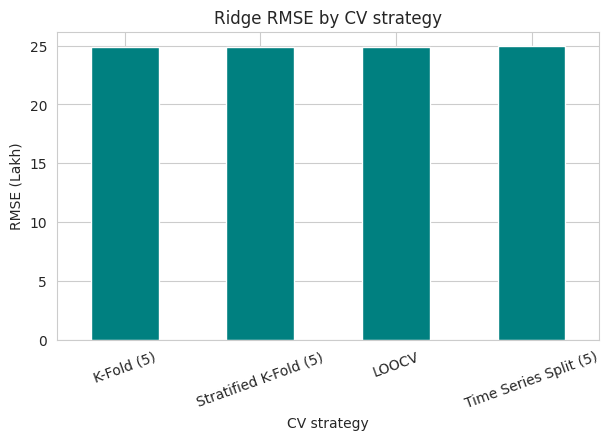

In [11]:
cv_table.set_index("CV strategy")["Mean RMSE"].plot.bar(figsize=(7,4), color="teal", title="Ridge RMSE by CV strategy")
plt.ylabel("RMSE (Lakh)"); plt.xticks(rotation=20); plt.savefig("plots/05_cv_compare.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** K-Fold, Stratified K-Fold and LOOCV give very similar estimates because the data is random (i.i.d.). Time Series Split can differ because it always trains on the past and tests on the future, so it is the most realistic for time-ordered data. LOOCV is the slowest.

## Part E: Tree-based models

In [12]:
gs_dt = GridSearchCV(DecisionTreeRegressor(random_state=RS),
                     {"max_depth": [3,5,7,10,None], "min_samples_leaf": [1,5,10,20]},
                     cv=kf, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
tree = record("Decision Tree", gs_dt)

# unlimited tree vs controlled tree (shows overfitting)
deep = DecisionTreeRegressor(random_state=RS).fit(X_train, y_train)
print("Unpruned tree  -> train R2: %.3f | test R2: %.3f" % (deep.score(X_train, y_train), deep.score(X_test, y_test)))
print("Tuned tree     -> train R2: %.3f | test R2: %.3f" % (tree.score(X_train, y_train), tree.score(X_test, y_test)))

Decision Tree | best params: {'max_depth': 7, 'min_samples_leaf': 20} | CV RMSE: 27.35
Unpruned tree  -> train R2: 1.000 | test R2: 0.869
Tuned tree     -> train R2: 0.926 | test R2: 0.907


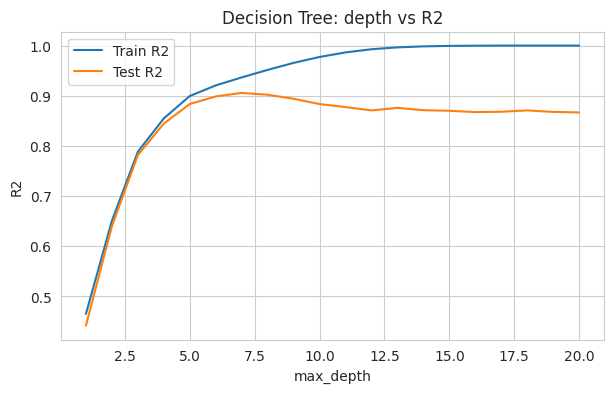

In [13]:
depths = range(1, 21); tr, te = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=RS).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
plt.figure(figsize=(7,4)); plt.plot(depths, tr, label="Train R2"); plt.plot(depths, te, label="Test R2")
plt.xlabel("max_depth"); plt.ylabel("R2"); plt.title("Decision Tree: depth vs R2"); plt.legend()
plt.savefig("plots/06_tree_depth.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** As depth increases, train R² keeps rising but test R² stops improving and then drops. This gap is overfitting. Limiting `max_depth` and `min_samples_leaf` controls it.

In [14]:
gs_rf = GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=RS, n_jobs=-1),
                     {"max_depth": [8, 12, None], "min_samples_leaf": [1, 3, 5]},
                     cv=kf, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
rf = record("Random Forest", gs_rf)

Random Forest | best params: {'max_depth': 12, 'min_samples_leaf': 5} | CV RMSE: 23.77


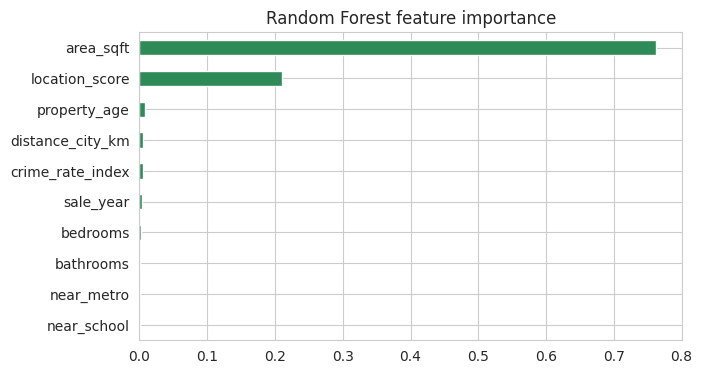

In [15]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(7,4), title="Random Forest feature importance", color="seagreen")
plt.savefig("plots/07_rf_importance.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Random Forest averages many trees, which reduces variance, so it is usually more stable than one tree. The chart shows which features matter most.

## Part F: Support Vector Regression

In [16]:
def tune_svr(kernel, grid):
    pipe = Pipeline([("sc", StandardScaler()), ("m", SVR(kernel=kernel))])
    return GridSearchCV(pipe, grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

gs_svr_lin = tune_svr("linear", {"m__C": [0.1, 1, 10, 100], "m__epsilon": [0.1, 1, 5]})
svr_lin = record("SVR (Linear)", gs_svr_lin)

gs_svr_rbf = tune_svr("rbf", {"m__C": [10, 100, 300], "m__gamma": ["scale", 0.01, 0.1], "m__epsilon": [0.1, 1, 5]})
svr_rbf = record("SVR (RBF)", gs_svr_rbf)

SVR (Linear) | best params: {'m__C': 100, 'm__epsilon': 5} | CV RMSE: 25.07


SVR (RBF) | best params: {'m__C': 300, 'm__epsilon': 0.1, 'm__gamma': 0.01} | CV RMSE: 22.25


**Interpretation:** `C` controls how strictly errors are punished, `epsilon` is the tolerance band where errors are ignored, and `gamma` controls how far one sample's influence reaches in the RBF kernel.

## Part G: Model comparison and evaluation

In [17]:
rows = []
for name, (tr_s, te_s, cv_rmse) in results.items():
    rows.append({"Model": name, "CV RMSE": cv_rmse,
                 "Train MSE": tr_s["MSE"], "Test MSE": te_s["MSE"],
                 "Train MAE": tr_s["MAE"], "Test MAE": te_s["MAE"],
                 "Train RMSE": tr_s["RMSE"], "Test RMSE": te_s["RMSE"],
                 "Train R2": tr_s["R2"], "Test R2": te_s["R2"]})
comp = pd.DataFrame(rows).set_index("Model")
comp["R2 gap"] = comp["Train R2"] - comp["Test R2"]
def diagnose(r):
    if r["Test R2"] < 0.6: return "Underfitting (low R2)"
    if r["R2 gap"] > 0.10: return "Overfitting (big train-test gap)"
    return "Good fit"
comp["Diagnosis"] = comp.apply(diagnose, axis=1)
comp = comp.round(3); comp.to_csv("results.csv"); comp

,CV RMSE,Train MSE,Test MSE,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2,R2 gap,Diagnosis
Model,,,,,,,,,,,
Ridge,24.951,616.266,644.983,18.967,19.446,24.825,25.397,0.917,0.920,-0.003,Good fit
Lasso,24.949,616.359,646.184,18.954,19.461,24.827,25.420,0.917,0.920,-0.002,Good fit
Decision Tree,27.353,552.418,752.504,17.675,20.356,23.504,27.432,0.926,0.907,0.019,Good fit
Random Forest,23.775,258.761,573.772,11.825,17.496,16.086,23.954,0.965,0.929,0.037,Good fit
SVR (Linear),25.068,624.647,658.681,18.827,19.374,24.993,25.665,0.916,0.918,-0.002,Good fit
SVR (RBF),22.252,465.090,493.034,15.865,16.229,21.566,22.204,0.938,0.939,-0.001,Good fit


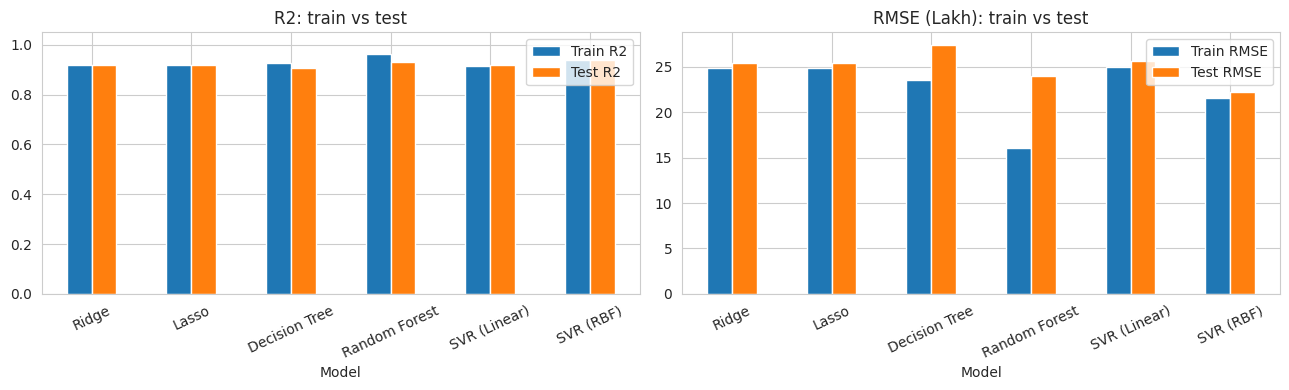

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
comp[["Train R2","Test R2"]].plot.bar(ax=ax[0], title="R2: train vs test"); ax[0].set_ylim(0,1.05)
comp[["Train RMSE","Test RMSE"]].plot.bar(ax=ax[1], title="RMSE (Lakh): train vs test")
for a in ax: a.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig("plots/08_model_compare.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Compare train vs test bars. A big gap means overfitting; low scores on both mean underfitting.

Best model (lowest CV RMSE): SVR (RBF)


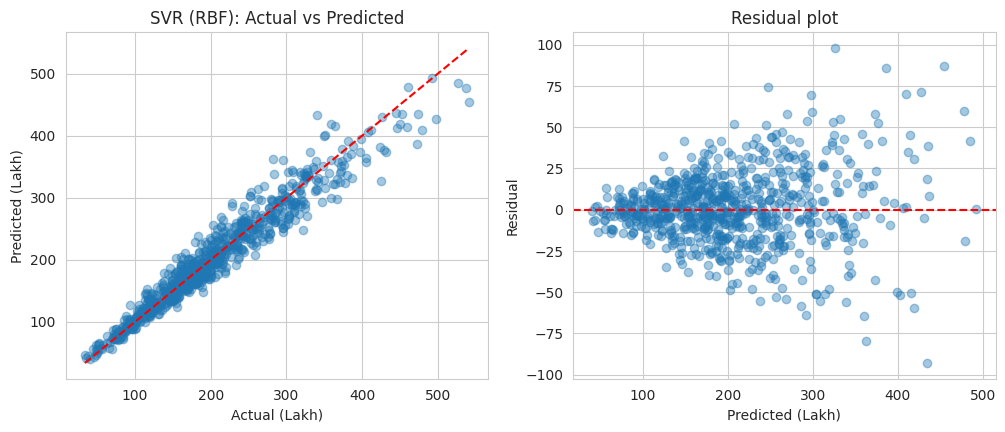

In [19]:
best_name = comp["CV RMSE"].idxmin()           # best by validation (CV) performance, not by test
models = {"Ridge": ridge, "Lasso": lasso, "Decision Tree": tree, "Random Forest": rf,
          "SVR (Linear)": svr_lin, "SVR (RBF)": svr_rbf}
best_model = models[best_name]
pred = best_model.predict(X_test)
print("Best model (lowest CV RMSE):", best_name)

fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
ax[0].scatter(y_test, pred, alpha=0.4); lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual (Lakh)"); ax[0].set_ylabel("Predicted (Lakh)"); ax[0].set_title(f"{best_name}: Actual vs Predicted")
ax[1].scatter(pred, y_test - pred, alpha=0.4); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted (Lakh)"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residual plot")
plt.savefig("plots/09_best_model.png", dpi=120, bbox_inches="tight"); plt.show()

**Interpretation:** Points close to the red diagonal mean accurate predictions. Residuals scattered randomly around zero mean there is no obvious systematic error.

## Save the best model (used by the Streamlit app)

In [20]:
joblib.dump({"model": best_model, "features": features, "name": best_name,
             "test_r2": float(comp.loc[best_name, "Test R2"]), "test_rmse": float(comp.loc[best_name, "Test RMSE"]),
             "ranges": {c: (float(df[c].min()), float(df[c].max())) for c in features}}, "model.pkl")
print("Saved model.pkl ->", best_name)

Saved model.pkl -> SVR (RBF)


## Part H: Final analysis

In [21]:
b = comp.loc[best_name]
print(f"1. BEST MODEL: {best_name} (lowest CV RMSE {b['CV RMSE']:.2f} lakh, test R2 {b['Test R2']:.3f}, test RMSE {b['Test RMSE']:.2f} lakh).")
print(f"2. REGULARIZATION: Unpruned tree R2 gap was {deep.score(X_train,y_train)-deep.score(X_test,y_test):.2f}; tuned tree gap is {comp.loc['Decision Tree','R2 gap']:.2f}. Ridge/Lasso alpha chosen by CV: {gs_ridge.best_params_['m__alpha']:.3f} / {gs_lasso.best_params_['m__alpha']:.3f}.")
print(f"3. CROSS-VALIDATION: RMSE across CV strategies ranged {cv_table['Mean RMSE'].min():.2f} to {cv_table['Mean RMSE'].max():.2f} lakh, so the estimates are stable.")
lin = comp.loc[["Ridge","Lasso"],"Test R2"].max(); non = comp.loc[["Decision Tree","Random Forest","SVR (RBF)"],"Test R2"].max()
print(f"4. LINEAR vs NON-LINEAR: best linear test R2 = {lin:.3f}; best non-linear test R2 = {non:.3f}.")
print(f"5. BUSINESS: On average the model is off by about {b['Test MAE']:.1f} lakh INR (MAE) per house on unseen data, useful for quick price estimates and sanity-checking listings.")

1. BEST MODEL: SVR (RBF) (lowest CV RMSE 22.25 lakh, test R2 0.939, test RMSE 22.20 lakh).
2. REGULARIZATION: Unpruned tree R2 gap was 0.13; tuned tree gap is 0.02. Ridge/Lasso alpha chosen by CV: 2.043 / 0.117.
3. CROSS-VALIDATION: RMSE across CV strategies ranged 24.89 to 24.95 lakh, so the estimates are stable.
4. LINEAR vs NON-LINEAR: best linear test R2 = 0.920; best non-linear test R2 = 0.939.
5. BUSINESS: On average the model is off by about 16.2 lakh INR (MAE) per house on unseen data, useful for quick price estimates and sanity-checking listings.
